# Taller propuesto. Lógica difusa con Wine y ajuste de un sistema difuso
**Inteligencia Computacional Aplicada, Maestría en Ciencias de la Información y las Comunicaciones, UDFJC**

Sergio Santiago Duarte Rojas, código 20261595002

El taller se resuelve en Python, como el cuaderno resuelto de la clase. Las seis tareas son las de la diapositiva del bloque 10 sobre Wine, y el último paso reproduce el ejemplo de `tunefis` de MathWorks. Las partes de MATLAB (el ejemplo de `tunefis` y el agrupamiento con `fcm` sobre los CSV exportados) están en los guiones `referencia_tunefis_matlab.m` y `puente_matlab_wine.m`.

## Paso 0. Preparar el entorno
Las mismas librerías, la misma semilla y la misma función `verificar` del cuaderno resuelto.

In [1]:
# ---- Preparación del entorno ----
import random, time, itertools
import numpy as np
import matplotlib.pyplot as plt

try:
    import skfuzzy as fuzz                       # scikit-fuzzy: se usa para COMPARAR con nuestro código
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()
print("NumPy", np.__version__, "| scikit-fuzzy", fuzz.__version__)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok

NumPy 2.4.6 | scikit-fuzzy 0.5.0


## Paso 1. Funciones del cuaderno resuelto
Se reutilizan sin cambios las funciones de pertenencia, el clasificador con reglas extraídas de los datos (Wang y Mendel simplificado), la carga de los conjuntos de scikit-learn y el Fuzzy C-Means propio.

In [2]:
# ---- Funciones de pertenencia (mismos parámetros que en MATLAB) ----
def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)

In [3]:
# ---- Clasificador difuso con reglas extraídas de los datos (Wang-Mendel simplificado) ----
ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    G = np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)
    return G

def extraer_reglas(Xn, y, n_mf):
    """Una regla por muestra (etiqueta dominante en cada característica); si dos muestras dan el mismo
    antecedente se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)                                     # N x F
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)                           # N x F x n_mf
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # N x n_reglas (t-norma = producto)
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")

In [4]:
# ---- Datos: conjuntos clásicos de la UCI incluidos en scikit-learn (no requieren internet) ----
def cargar_crudo(nombre="iris", test=0.3):
    from sklearn.datasets import load_iris, load_wine, load_breast_cancer
    from sklearn.model_selection import train_test_split
    d = {"iris": load_iris, "wine": load_wine, "breast_cancer": load_breast_cancer}[nombre]()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=test, stratify=d.target, random_state=SEMILLA)
    return dict(nombre=nombre, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte,
                car=list(d.feature_names), clases=[str(t) for t in d.target_names])

In [5]:
# ---- Fuzzy C-Means propio ----
def fcm_propio(X, c=3, m=2.0, iters=300, tol=1e-6, semilla=SEMILLA):
    """X: N x d. Devuelve centros (c x d), U (c x N), historial del objetivo J."""
    rng = np.random.default_rng(semilla)
    U = rng.random((c, len(X))); U /= U.sum(axis=0, keepdims=True)
    J = []
    for _ in range(iters):
        Um = U ** m
        centros = (Um @ X) / Um.sum(axis=1, keepdims=True)
        d = np.linalg.norm(X[None, :, :] - centros[:, None, :], axis=2) + 1e-12      # c x N
        J.append(float((Um * d ** 2).sum()))
        U_nueva = 1.0 / ((d[:, None, :] / d[None, :, :]) ** (2.0 / (m - 1))).sum(axis=1)
        if np.abs(U_nueva - U).max() < tol:
            U = U_nueva; break
        U = U_nueva
    return centros, U, J

def coeficiente_particion(U):
    """FPC = (1/N) * sum de U^2; vale 1/c con partición totalmente borrosa y 1 con partición nítida."""
    return float((U ** 2).sum() / U.shape[1])

## Paso 2. Wine y la elección de cuatro características (TODO 1)
Wine describe 178 vinos de tres cultivares con 13 medidas químicas. Con 13 características y 3 etiquetas la rejilla completa tendría $3^{13}$ reglas, así que primero se eligen 4. La elección se hace solo con el entrenamiento, porque si mirara la prueba la exactitud final dejaría de ser una estimación honesta.

El criterio es la razón F del análisis de varianza, que compara la varianza de las medias de las clases con la varianza dentro de cada clase. Una característica con F alta separa bien los cultivares por sí sola.

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_selection import f_classif
d = cargar_crudo("wine")
d["clases"] = ["cultivar 1", "cultivar 2", "cultivar 3"]
d["car"] = ["alcohol", "ácido málico", "ceniza", "alcalinidad de la ceniza", "magnesio", "fenoles totales",
            "flavonoides", "fenoles no flavonoides", "proantocianidinas", "intensidad de color", "tono",
            "OD280/OD315", "prolina"]
print(len(d["Xtr"]), "vinos de entrenamiento,", len(d["Xte"]), "de prueba y", len(d["car"]), "características")

# ===== TODO 1: elija 4 características usando solo el entrenamiento =====
def elegir_caracteristicas(X, y, k=4):
    F, _ = f_classif(X, y)
    return np.argsort(-F)[:k], F

idx, F_tr = elegir_caracteristicas(d["Xtr"], d["ytr"])
# ===== fin TODO 1 =====

car4 = [d["car"][i] for i in idx]
for i in np.argsort(-F_tr):
    print(f"{d['car'][i]:<26} F = {F_tr[i]:6.1f}" + ("   <- elegida" if i in idx else ""))
print("\nCorrelación entre las elegidas (entrenamiento):")
print(np.round(np.corrcoef(d["Xtr"][:, idx].T), 2))

124 vinos de entrenamiento, 54 de prueba y 13 características
flavonoides                F =  187.7   <- elegida
prolina                    F =  149.4   <- elegida
OD280/OD315                F =  126.6   <- elegida
alcohol                    F =  100.3   <- elegida
intensidad de color        F =   84.0
tono                       F =   72.3
fenoles totales            F =   59.3
alcalinidad de la ceniza   F =   26.1
ácido málico               F =   22.6
proantocianidinas          F =   20.0
fenoles no flavonoides     F =   17.9
ceniza                     F =   11.6
magnesio                   F =    7.1

Correlación entre las elegidas (entrenamiento):
[[1.   0.5  0.77 0.3 ]
 [0.5  1.   0.32 0.66]
 [0.77 0.32 1.   0.1 ]
 [0.3  0.66 0.1  1.  ]]


In [7]:
# PUNTO DE CONTROL 1
verificar("Se eligieron 4 características distintas", len(set(idx.tolist())) == 4, "")
verificar("Las elegidas tienen la mayor razón F del entrenamiento", F_tr[idx].min() >= np.delete(F_tr, idx).max(), "")
mins, maxs = d["Xtr"][:, idx].min(0), d["Xtr"][:, idx].max(0)          # solo con entrenamiento
Xtr, Xte = normalizar(d["Xtr"][:, idx], mins, maxs), normalizar(d["Xte"][:, idx], mins, maxs)
verificar("El entrenamiento normalizado cubre exactamente [0, 1]", np.allclose(Xtr.min(0), 0) and np.allclose(Xtr.max(0), 1), "")

[OK]      Se eligieron 4 características distintas
[OK]      Las elegidas tienen la mayor razón F del entrenamiento
[OK]      El entrenamiento normalizado cubre exactamente [0, 1]


True

## Paso 3. La función sigmoidal (TODO 2)
MATLAB define `sigmf(x,[a c])` como $1/(1+e^{-a(x-c)})$. El parámetro $a$ fija la pendiente y el sentido de la curva, y $c$ el punto donde el grado vale 0.5. Sirve para etiquetas abiertas en un extremo, como «alto» sin límite superior.

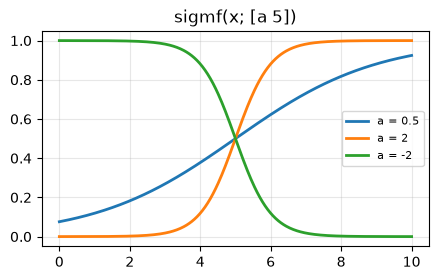

In [8]:
# ===== TODO 2: implemente sigmf con el orden de MATLAB [a c] =====
def sigmf(x, a, c):
    """Sigmoidal [a c]: 1 / (1 + exp(-a (x - c)))."""
    x = np.asarray(x, dtype=float)
    return 1.0 / (1.0 + np.exp(-a * (x - c)))
# ===== fin TODO 2 =====
_MF["sigmf"] = sigmf

x = np.linspace(0, 10, 400)
plt.figure(figsize=(5, 2.8))
for a in (0.5, 2, -2):
    plt.plot(x, sigmf(x, a, 5), lw=2, label=f"a = {a}")
plt.title("sigmf(x; [a 5])"); plt.grid(alpha=.3); plt.legend(fontsize=8); plt.show()

In [9]:
# PUNTO DE CONTROL 2
xs = np.linspace(0, 10, 101)
verificar("sigmf(c; [a c]) = 0.5", abs(float(sigmf(4, 2, 4)) - 0.5) < 1e-12, "en x = c el grado es 0.5")
verificar("sigmf(5; [2 4]) = 1/(1+e^-2) = 0.8808", abs(float(sigmf(5, 2, 4)) - 0.8808) < 1e-4, "revise el signo del exponente")
verificar("sigmf coincide con scikit-fuzzy", np.allclose(sigmf(xs, 2, 4), fuzz.sigmf(xs, 4, 2)), "scikit-fuzzy usa (x, centro, pendiente)")

[OK]      sigmf(c; [a c]) = 0.5
[OK]      sigmf(5; [2 4]) = 1/(1+e^-2) = 0.8808
[OK]      sigmf coincide con scikit-fuzzy


True

## Paso 4. Fuerza de las reglas con mínimo y producto (TODO 3)
La fuerza de una regla es la t-norma de los grados de sus antecedentes. El cuaderno resuelto usa el producto. Aquí la función admite las dos t-normas y se comparan sobre la prueba con $n = 3$ etiquetas por característica.

In [10]:
# ===== TODO 3: fuerza de cada regla con la t-norma mínimo o producto =====
def fuerza_reglas(G, R, tnorma="prod"):
    """G: N x F x n_mf grados de pertenencia. R: n_reglas x F etiquetas. Devuelve N x n_reglas."""
    grados = G[:, np.arange(G.shape[1])[None, :], R]          # N x n_reglas x F
    return grados.min(axis=2) if tnorma == "min" else grados.prod(axis=2)
# ===== fin TODO 3 =====

def predecir_tnorma(Xn, R, clases, n_mf, tnorma="prod", defecto=0):
    fuerza = fuerza_reglas(grados_pertenencia(Xn, n_mf), R, tnorma)
    pred = clases[fuerza.argmax(axis=1)]
    return np.where(fuerza.max(axis=1) > 0, pred, defecto), fuerza

N_MF = 3
R, clases_r, grados_r = extraer_reglas(Xtr, d["ytr"], N_MF)
pred_prod, f_prod = predecir_tnorma(Xte, R, clases_r, N_MF, "prod")
pred_min, f_min = predecir_tnorma(Xte, R, clases_r, N_MF, "min")
print("Reglas:", len(R), "de", len(Xtr), "muestras de entrenamiento")
print("Exactitud en prueba con producto: %.3f | con mínimo: %.3f" % (accuracy_score(d["yte"], pred_prod), accuracy_score(d["yte"], pred_min)))
print("Predicciones que cambian al pasar del producto al mínimo:", int((pred_prod != pred_min).sum()))
reglas_en_palabras(R, clases_r, grados_r, car4, d["clases"], N_MF, max_reglas=6)

Reglas: 31 de 124 muestras de entrenamiento
Exactitud en prueba con producto: 0.926 | con mínimo: 0.926
Predicciones que cambian al pasar del producto al mínimo: 0
SI flavonoides es medio Y prolina es medio Y OD280/OD315 es medio Y alcohol es medio ENTONCES clase = cultivar 2   (grado 0.60)
SI flavonoides es medio Y prolina es bajo Y OD280/OD315 es medio Y alcohol es bajo ENTONCES clase = cultivar 2   (grado 0.58)
SI flavonoides es medio Y prolina es bajo Y OD280/OD315 es medio Y alcohol es medio ENTONCES clase = cultivar 2   (grado 0.54)
SI flavonoides es bajo Y prolina es medio Y OD280/OD315 es medio Y alcohol es medio ENTONCES clase = cultivar 3   (grado 0.52)
SI flavonoides es alto Y prolina es medio Y OD280/OD315 es medio Y alcohol es alto ENTONCES clase = cultivar 1   (grado 0.49)
SI flavonoides es bajo Y prolina es medio Y OD280/OD315 es bajo Y alcohol es medio ENTONCES clase = cultivar 3   (grado 0.47)


In [11]:
# PUNTO DE CONTROL 3
verificar("El producto no supera al mínimo (propiedad de las t-normas, control del código)", np.all(f_prod <= f_min + 1e-12), "")
verificar("Con el producto coincide con predecir_reglas del cuaderno resuelto", np.array_equal(pred_prod, predecir_reglas(Xte, R, clases_r, N_MF)[0]), "")

[OK]      El producto no supera al mínimo (propiedad de las t-normas, control del código)


[OK]      Con el producto coincide con predecir_reglas del cuaderno resuelto


True

**Análisis adicional.** Toda t-norma crece con cada argumento. Si existe la regla formada por la etiqueta de mayor grado en cada característica (la celda propia del vino), esa regla es la más fuerte con el mínimo, con el producto y con cualquier otra t-norma. Se cuenta para cuántos vinos de prueba existe, y qué tan lejos queda la mejor regla de otra clase.

In [12]:
# ===== Análisis adicional: celda propia y margen de la regla ganadora =====
def origen_decision(Xn, R, n_mf, tnorma="prod"):
    """Para cada dato: 0 si decide su celda propia, 1 si decide otra regla, 2 si ninguna regla se activa."""
    G = grados_pertenencia(Xn, n_mf)
    fuerza = fuerza_reglas(G, R, tnorma)
    propia = G.argmax(axis=2)
    gana = R[fuerza.argmax(axis=1)]
    origen = np.where((gana == propia).all(axis=1), 0, 1)
    return np.where(fuerza.max(axis=1) > 0, origen, 2)

org3 = origen_decision(Xte, R, N_MF)
print("Con n = 3, decide la celda propia en", int((org3 == 0).sum()), "vinos, otra regla en", int((org3 == 1).sum()),
      "y ninguna regla en", int((org3 == 2).sum()))
rival = np.array([f_prod[k][clases_r != clases_r[f_prod[k].argmax()]].max() / f_prod[k].max() for k in range(len(Xte))])
print("La mejor regla de otra clase tiene, en mediana, el %.0f %% de la fuerza de la ganadora" % (100 * np.median(rival)))
errores = np.where(pred_prod != d["yte"])[0]
print("De los", len(errores), "errores,", int((org3[errores] == 0).sum()), "deciden por su celda propia")

def composicion_celda(regla, Xn_tr, y_tr, n_mf):
    """Vinos de entrenamiento por cultivar cuya celda propia es el antecedente de la regla."""
    propia_tr = grados_pertenencia(Xn_tr, n_mf).argmax(axis=2)
    return np.bincount(y_tr[(propia_tr == regla).all(axis=1)], minlength=3).tolist()

for k in errores:
    regla = R[f_prod[k].argmax()]
    print(f"   error: {d['clases'][d['yte'][k]]} tomado por {d['clases'][pred_prod[k]]} | vinos de entrenamiento en esa celda por cultivar: {composicion_celda(regla, Xtr, d['ytr'], N_MF)}")
mayoria = [int(np.argmax(composicion_celda(r, Xtr, d["ytr"], N_MF))) for r in R]
print("Reglas cuyo consecuente no es la mayoría de su celda en el entrenamiento:", int(np.sum(np.array(mayoria) != clases_r)), "de", len(R))

Con n = 3, decide la celda propia en 52 vinos, otra regla en 2 y ninguna regla en 0
La mejor regla de otra clase tiene, en mediana, el 18 % de la fuerza de la ganadora
De los 4 errores, 4 deciden por su celda propia
   error: cultivar 1 tomado por cultivar 2 | vinos de entrenamiento en esa celda por cultivar: [9, 7, 0]
   error: cultivar 2 tomado por cultivar 1 | vinos de entrenamiento en esa celda por cultivar: [4, 0, 0]
   error: cultivar 2 tomado por cultivar 3 | vinos de entrenamiento en esa celda por cultivar: [0, 0, 1]
   error: cultivar 2 tomado por cultivar 3 | vinos de entrenamiento en esa celda por cultivar: [0, 1, 15]
Reglas cuyo consecuente no es la mayoría de su celda en el entrenamiento: 1 de 31


## Paso 5. Matriz de confusión y par más confundido (TODO 4)

In [13]:
# ===== TODO 4: matriz de confusión y par (real, predicha) con más errores =====
cm = confusion_matrix(d["yte"], pred_prod)
fuera = cm.copy(); np.fill_diagonal(fuera, 0)
par = tuple(int(v) for v in np.unravel_index(np.argmax(fuera), fuera.shape))
# ===== fin TODO 4 =====

print(cm)
print("Par más confundido:", d["clases"][par[0]], "tomado por", d["clases"][par[1]], f"({cm[par]} veces)")
print("Fuerza de la regla ganadora en los errores:", np.round(f_prod[errores].max(axis=1), 3))
print("Mediana de esa fuerza en los aciertos:", round(float(np.median(f_prod[pred_prod == d["yte"]].max(axis=1))), 3))

[[17  1  0]
 [ 1 18  2]
 [ 0  0 15]]
Par más confundido: cultivar 2 tomado por cultivar 3 (2 veces)
Fuerza de la regla ganadora en los errores: [0.445 0.378 0.17  0.173]
Mediana de esa fuerza en los aciertos: 0.255


In [14]:
# PUNTO DE CONTROL 4
verificar("La matriz suma el número de muestras de prueba", cm.sum() == len(d["yte"]), "")
verificar("El par está fuera de la diagonal", par[0] != par[1], "fill_diagonal con cero antes de argmax")
verificar("El par tiene el mayor número de errores", cm[par] == fuera.max(), "")

[OK]      La matriz suma el número de muestras de prueba
[OK]      El par está fuera de la diagonal
[OK]      El par tiene el mayor número de errores


np.True_

## Paso 6. Etiquetas, reglas, exactitud y árbol (TODO 5)
Se varía el número de etiquetas $n$ y se compara con un árbol de decisión al que se le permiten hasta tantas hojas como reglas, sobre las mismas 4 características.

**Predicción antes de ejecutar.** El número de reglas crece con $n$ hasta acercarse al de muestras de entrenamiento. La exactitud no debería subir siempre, porque con muchas etiquetas cada regla queda respaldada por muy pocos vinos.

In [15]:
# ===== TODO 5: variar n, contar reglas y comparar con un árbol con el mismo límite de hojas =====
from sklearn.tree import DecisionTreeClassifier
filas = []
for n in (2, 3, 4, 5):
    Rn, cn, gn = extraer_reglas(Xtr, d["ytr"], n)
    pn, _ = predecir_tnorma(Xte, Rn, cn, n)
    arbol = DecisionTreeClassifier(max_leaf_nodes=max(2, len(Rn)), random_state=SEMILLA)
    arbol.fit(d["Xtr"][:, idx], d["ytr"])
    pa = arbol.predict(d["Xte"][:, idx])
    filas.append((n, len(Rn), accuracy_score(d["yte"], pn), accuracy_score(d["yte"], pa), int(arbol.get_n_leaves())))
# ===== fin TODO 5 =====

print(f"{'n_mf':>5} {'reglas':>7} {'exact. difusa':>14} {'exact. árbol':>13} {'hojas usadas':>13}")
for n, nr, a1, a2, h in filas:
    print(f"{n:>5} {nr:>7} {a1:>14.3f} {a2:>13.3f} {h:>13}")
print("\nRejilla completa con 4 características:", [n ** 4 for n in (2, 3, 4, 5)])
print("Un acierto en prueba vale %.1f puntos" % (100 / len(d["yte"])))

 n_mf  reglas  exact. difusa  exact. árbol  hojas usadas
    2      10          0.759         0.870            10
    3      31          0.926         0.870            13
    4      43          0.889         0.870            13
    5      71          0.926         0.870            13

Rejilla completa con 4 características: [16, 81, 256, 625]
Un acierto en prueba vale 1.9 puntos


In [16]:
# PUNTO DE CONTROL 5
reglas_n = [f[1] for f in filas]
verificar("El número de reglas crece al aumentar n", all(b >= a for a, b in zip(reglas_n, reglas_n[1:])), "")
verificar("Ninguna cantidad de reglas supera n^4 ni el número de muestras", all(f[1] <= min(f[0] ** 4, len(Xtr)) for f in filas), "")

[OK]      El número de reglas crece al aumentar n
[OK]      Ninguna cantidad de reglas supera n^4 ni el número de muestras


True

**Análisis adicional.** Elegir $n$ con la tabla anterior sería usar la prueba para decidir. Se elige con validación cruzada de 5 particiones dentro del entrenamiento, repitiendo en cada partición la elección de características y la normalización, y con el árbol en las mismas particiones. Se toma el $n$ más simple cuya exactitud media no queda más de un error estándar por debajo de la mejor, una adaptación del criterio de la clase que no usa la prueba. Para ver si la elección depende de cómo se parte el entrenamiento, la validación se repite con las semillas 0 a 49.

In [17]:
# ===== Análisis adicional: elegir n con validación cruzada en el entrenamiento =====
from sklearn.model_selection import StratifiedKFold
def validar(semilla):
    pliegues = StratifiedKFold(5, shuffle=True, random_state=semilla)
    acc = {n: [] for n in (2, 3, 4, 5, "árbol")}
    for itr, iva in pliegues.split(d["Xtr"], d["ytr"]):
        ik, _ = elegir_caracteristicas(d["Xtr"][itr], d["ytr"][itr])
        mn, mx = d["Xtr"][itr][:, ik].min(0), d["Xtr"][itr][:, ik].max(0)
        for n in (2, 3, 4, 5):
            Rn, cn, _ = extraer_reglas(normalizar(d["Xtr"][itr][:, ik], mn, mx), d["ytr"][itr], n)
            pn, _ = predecir_tnorma(normalizar(d["Xtr"][iva][:, ik], mn, mx), Rn, cn, n)
            acc[n].append(accuracy_score(d["ytr"][iva], pn))
        arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(d["Xtr"][itr][:, ik], d["ytr"][itr])
        acc["árbol"].append(accuracy_score(d["ytr"][iva], arbol.predict(d["Xtr"][iva][:, ik])))
    return {k: (float(np.mean(v)), float(np.std(v, ddof=1))) for k, v in acc.items()}

exact_cv = validar(SEMILLA)
for k, (m, s) in exact_cv.items():
    print(f"{str(k):>6}   exactitud de validación {m:.3f} ± {s:.3f}")
mejor_n = max((2, 3, 4, 5), key=lambda n: exact_cv[n][0])
n_elegido = min(n for n in (2, 3, 4, 5) if exact_cv[n][0] >= exact_cv[mejor_n][0] - exact_cv[mejor_n][1] / np.sqrt(5))
print("Mejor n por validación:", mejor_n, "| el más simple a un error estándar de él:", n_elegido)

repetidas = [validar(s) for s in range(50)]
gana = [max((2, 3, 4, 5), key=lambda n: r[n][0]) for r in repetidas]
print("\nEn 50 repeticiones gana cada n:", {n: gana.count(n) for n in (2, 3, 4, 5)})
print("Exactitud media en las 50 repeticiones:", {k: round(float(np.mean([r[k][0] for r in repetidas])), 3) for k in (2, 3, 4, 5, "árbol")})
print("Repeticiones en que n = 4 supera al árbol:", sum(r[4][0] > r["árbol"][0] for r in repetidas), "de", len(repetidas))

     2   exactitud de validación 0.831 ± 0.065
     3   exactitud de validación 0.839 ± 0.027
     4   exactitud de validación 0.944 ± 0.045
     5   exactitud de validación 0.896 ± 0.092
 árbol   exactitud de validación 0.919 ± 0.040
Mejor n por validación: 4 | el más simple a un error estándar de él: 4



En 50 repeticiones gana cada n: {2: 0, 3: 0, 4: 45, 5: 5}
Exactitud media en las 50 repeticiones: {2: 0.814, 3: 0.861, 4: 0.936, 5: 0.914, 'árbol': 0.888}
Repeticiones en que n = 4 supera al árbol: 50 de 50


**Análisis adicional.** El modelo que se reporta es el de $n$ elegido por validación. Se mide una sola vez en prueba, se cuenta de dónde sale cada decisión y se compara con el de $n = 3$ y con el árbol mediante la prueba exacta de McNemar, que cuenta los vinos en que dos modelos discrepan.

In [18]:
# ===== Análisis adicional: el modelo elegido en prueba =====
from scipy.stats import binomtest
R_e, c_e, g_e = extraer_reglas(Xtr, d["ytr"], n_elegido)
pred_e, f_e = predecir_tnorma(Xte, R_e, c_e, n_elegido)
cm_e = confusion_matrix(d["yte"], pred_e)
print("n =", n_elegido, "|", len(R_e), "reglas | exactitud en prueba %.3f" % accuracy_score(d["yte"], pred_e))
print(cm_e)
org_e = origen_decision(Xte, R_e, n_elegido)
for k in np.where(pred_e != d["yte"])[0]:
    origen = ["celda propia", "otra regla", "ninguna regla, clase por defecto"][org_e[k]]
    comp = composicion_celda(R_e[f_e[k].argmax()], Xtr, d["ytr"], n_elegido) if org_e[k] < 2 else "-"
    print(f"   error: {d['clases'][d['yte'][k]]} tomado por {d['clases'][pred_e[k]]} | decide {origen} | celda en entrenamiento {comp}")
for n in (2, 3, 4, 5):
    Rn, cn, _ = extraer_reglas(Xtr, d["ytr"], n)
    o = origen_decision(Xte, Rn, n)
    print(f"n = {n}: celda propia {int((o == 0).sum())}, otra regla {int((o == 1).sum())}, ninguna regla {int((o == 2).sum())}")

def mcnemar(p1, p2, y):
    b, c = int(np.sum((p1 == y) & (p2 != y))), int(np.sum((p1 != y) & (p2 == y)))
    return b, c, (binomtest(b, b + c).pvalue if b + c else 1.0)
arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(d["Xtr"][:, idx], d["ytr"])
pred_arbol = arbol.predict(d["Xte"][:, idx])
for nombre, p in (("n = 3", pred_prod), ("árbol", pred_arbol)):
    b, c, pv = mcnemar(pred_e, p, d["yte"])
    print(f"McNemar, n = {n_elegido} frente a {nombre}: {b} aciertos solo del primero, {c} solo del segundo, p = {pv:.3f}")
a = accuracy_score(d["yte"], pred_e); z = 1.96; N = len(d["yte"])
centro = (a + z**2 / (2 * N)) / (1 + z**2 / N); radio = z * np.sqrt(a * (1 - a) / N + z**2 / (4 * N**2)) / (1 + z**2 / N)
print("Intervalo de Wilson del 95 %% para la exactitud: [%.3f, %.3f]" % (centro - radio, centro + radio))

n = 4 | 43 reglas | exactitud en prueba 0.889
[[18  0  0]
 [ 3 15  3]
 [ 0  0 15]]
   error: cultivar 2 tomado por cultivar 1 | decide ninguna regla, clase por defecto | celda en entrenamiento -
   error: cultivar 2 tomado por cultivar 1 | decide otra regla | celda en entrenamiento [1, 0, 0]
   error: cultivar 2 tomado por cultivar 3 | decide celda propia | celda en entrenamiento [0, 1, 1]
   error: cultivar 2 tomado por cultivar 3 | decide celda propia | celda en entrenamiento [0, 1, 1]
   error: cultivar 2 tomado por cultivar 1 | decide celda propia | celda en entrenamiento [1, 0, 0]
   error: cultivar 2 tomado por cultivar 3 | decide celda propia | celda en entrenamiento [0, 0, 3]
n = 2: celda propia 54, otra regla 0, ninguna regla 0
n = 3: celda propia 52, otra regla 2, ninguna regla 0
n = 4: celda propia 47, otra regla 6, ninguna regla 1
n = 5: celda propia 45, otra regla 7, ninguna regla 2
McNemar, n = 4 frente a n = 3: 1 aciertos solo del primero, 3 solo del segundo, p = 0.625
M

## Paso 7. Fuzzy C-Means y exportación para MATLAB (TODO 6)
FCM agrupa los 178 vinos con las 4 características elegidas y sin mirar el cultivar. Los grupos se comparan con los cultivares mediante el ARI. Además se exportan el entrenamiento y la prueba a CSV para leerlos en MATLAB con `readmatrix` y usar `genfis` o `fcm`, y el grupo de cada vino para comparar con el `fcm` de MATLAB.

Iteraciones: 19 | J final: 7.439
ARI  FCM: 0.794 | k-means: 0.792 | coeficiente de partición: 0.690
Centros (escala [0, 1]):
 [[0.3883 0.1626 0.6146 0.3151]
 [0.5605 0.6061 0.6884 0.7176]
 [0.1179 0.2474 0.1724 0.5343]]
Grupo frente a cultivar:
 [[ 2 60  0]
 [57  1  0]
 [ 0 10 48]]
Vinos con grado máximo menor que 0.6: 20 | del cultivar 2: 14


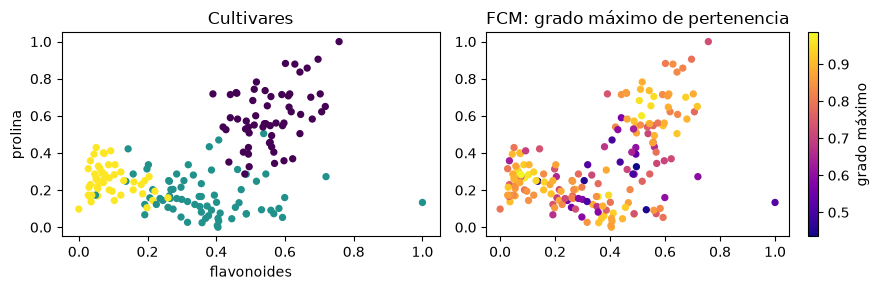

In [19]:
# ===== TODO 6: FCM sobre las 4 características y exportación de CSV para MATLAB =====
import pandas as pd
X_all = np.vstack([d["Xtr"], d["Xte"]])[:, idx]; y_all = np.concatenate([d["ytr"], d["yte"]])
Xa = normalizar(X_all, X_all.min(0), X_all.max(0))
centros, U, J = fcm_propio(Xa, c=3, m=2.0)
for nombre, X_, y_ in (("train", d["Xtr"], d["ytr"]), ("test", d["Xte"], d["yte"])):
    tabla = pd.DataFrame(X_[:, idx], columns=car4)
    tabla["clase"] = y_ + 1                                   # MATLAB numera desde 1
    tabla.to_csv(f"wine_4car_{nombre}.csv", index=False)
pd.DataFrame({"grupo_python": U.argmax(axis=0) + 1}).to_csv("wine_fcm_python.csv", index=False)
# ===== fin TODO 6 =====

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
ari_fcm = adjusted_rand_score(y_all, U.argmax(axis=0))
ari_km = adjusted_rand_score(y_all, KMeans(3, n_init=10, random_state=SEMILLA).fit_predict(Xa))
fpc = coeficiente_particion(U)
print("Iteraciones:", len(J), "| J final: %.3f" % J[-1])
print("ARI  FCM: %.3f | k-means: %.3f | coeficiente de partición: %.3f" % (ari_fcm, ari_km, fpc))
print("Centros (escala [0, 1]):\n", np.round(centros, 4))
print("Grupo frente a cultivar:\n", pd.crosstab(U.argmax(axis=0) + 1, y_all + 1).to_numpy())
bajo = U.max(axis=0) < 0.6
print("Vinos con grado máximo menor que 0.6:", int(bajo.sum()), "| del cultivar 2:", int(np.sum(y_all[bajo] == 1)))
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.scatter(Xa[:, 0], Xa[:, 1], c=y_all, cmap="viridis", s=18); plt.xlabel(car4[0]); plt.ylabel(car4[1]); plt.title("Cultivares")
plt.subplot(1, 2, 2); plt.scatter(Xa[:, 0], Xa[:, 1], c=U.max(axis=0), cmap="plasma", s=18); plt.colorbar(label="grado máximo"); plt.title("FCM: grado máximo de pertenencia")
plt.tight_layout(); plt.show()

In [20]:
# PUNTO DE CONTROL 6
verificar("Los grados de cada vino suman 1", np.allclose(U.sum(axis=0), 1), "")
verificar("El objetivo J no aumenta", all(b <= a + 1e-9 for a, b in zip(J, J[1:])), "")
verificar("ARI de FCM > 0.5", ari_fcm > 0.5, "")
cs, Us, *_ = fuzz.cluster.cmeans(Xa.T, 3, 2, error=1e-6, maxiter=300, seed=SEMILLA)
verificar("Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0.9)", adjusted_rand_score(U.argmax(axis=0), Us.argmax(axis=0)) > 0.9, "")
leidos = [pd.read_csv(f"wine_4car_{n}.csv") for n in ("train", "test")]
verificar("Los CSV tienen las filas y columnas esperadas", [t.shape for t in leidos] == [(len(d["Xtr"]), 5), (len(d["Xte"]), 5)], "")

[OK]      Los grados de cada vino suman 1
[OK]      El objetivo J no aumenta
[OK]      ARI de FCM > 0.5
[OK]      Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0.9)
[OK]      Los CSV tienen las filas y columnas esperadas


True

## Paso 8. Ajuste de un sistema difuso (Tune FIS)
El ejemplo de MathWorks `openExample('fuzzy/TuneAFuzzyInferenceSystemExample')` aproxima $y = \sin(2x)/e^{x/5}$ con $x$ de 0 a 10 en pasos de 0.1. `genfis` con partición en rejilla crea un Sugeno de primer orden con 5 campanas generalizadas (`gbellmf`) en la entrada y 5 reglas cuyo consecuente es $p_i x + r_i$, todas en cero. `tunefis` con el método ANFIS ajusta los 25 parámetros durante 10 épocas.

ANFIS es un aprendizaje híbrido. En cada época, con las campanas fijas, la salida es lineal en los consecuentes y estos se resuelven por mínimos cuadrados. Después, con los consecuentes fijos, los parámetros de las campanas dan un paso de descenso de gradiente cuya longitud es el tamaño de paso. Ese tamaño empieza en 0.01, sube un 10 % tras cuatro reducciones seguidas del error, baja un 10 % tras dos combinaciones seguidas de una subida y una bajada, y tras cada cambio espera cuatro épocas antes de volver a evaluarse. Aquí se programa ese algoritmo y se compara época por época con lo que imprime MATLAB R2026a al ejecutar `referencia_tunefis_matlab.m`.

In [21]:
# ---- ANFIS de una entrada: Sugeno de primer orden con campanas generalizadas ----
def gbellmf(x, a, b, c):
    """Campana generalizada [a b c] (mismo orden que MATLAB)."""
    return 1.0 / (1.0 + np.abs((np.asarray(x, dtype=float) - c) / a) ** (2 * b))

def genfis_rejilla(x, n_mf):
    """Como genfis con GridPartition y gbellmf: centros uniformes, a = rango/(2(n-1)), b = 2."""
    lo, hi = float(np.min(x)), float(np.max(x))
    a = (hi - lo) / (2 * (n_mf - 1))
    return np.array([[a, 2.0, c] for c in np.linspace(lo, hi, n_mf)]), np.zeros((n_mf, 2))

def sugeno1(x, P, L):
    """Salida = suma de w_i (p_i x + r_i) / suma de w_i. P: campanas, L: consecuentes [p r]."""
    W = np.stack([gbellmf(x, *p) for p in P], axis=1)
    f = L[:, 0][None, :] * x[:, None] + L[:, 1][None, :]
    return (W * f).sum(axis=1) / W.sum(axis=1), W, f

def consecuentes_mco(x, y, P):
    """Con las campanas fijas la salida es lineal en [p r]: mínimos cuadrados."""
    W = np.stack([gbellmf(x, *p) for p in P], axis=1)
    Wn = W / W.sum(axis=1, keepdims=True)
    th, *_ = np.linalg.lstsq(np.hstack([Wn * x[:, None], Wn]), y, rcond=None)
    return np.stack([th[:len(P)], th[len(P):]], axis=1)

def gradiente_premisas(x, y, P, L):
    """Derivada del error cuadrático total respecto de [a b c] de cada campana."""
    yh, W, f = sugeno1(x, P, L)
    e, S, G = y - yh, W.sum(axis=1), np.zeros_like(P)
    for j, (a, b, c) in enumerate(P):
        t = (x - c) / a
        u = np.abs(t) ** (2 * b); mu = 1.0 / (1.0 + u)
        t_seguro = np.where(t == 0, 1.0, t)
        d_a = 2 * b * mu ** 2 * u / a
        d_b = np.where(t == 0, 0.0, -2 * mu ** 2 * u * np.log(np.abs(t_seguro)))
        d_c = np.where(t == 0, 0.0, 2 * b * mu ** 2 * u / (a * t_seguro))
        dy_dw = (f[:, j] - yh) / S
        G[j] = [np.sum(-2 * e * dy_dw * dmu) for dmu in (d_a, d_b, d_c)]
    return G

def anfis(x, y, P0, epocas=10, paso=0.01, baja=0.9, sube=1.1, x_val=None, y_val=None):
    """Aprendizaje híbrido de ANFIS. Devuelve el historial y el sistema de menor error
    (de validación si se da, si no de entrenamiento), como tunefis."""
    P = P0.copy().astype(float)
    hist = {"rmse": [], "rmse_val": [], "paso": []}
    mejor, ultimo_cambio = None, 0
    for ep in range(1, epocas + 1):
        L = consecuentes_mco(x, y, P)
        rmse = float(np.sqrt(np.mean((y - sugeno1(x, P, L)[0]) ** 2)))
        hist["rmse"].append(rmse); hist["paso"].append(paso)
        criterio = rmse
        if x_val is not None:
            criterio = float(np.sqrt(np.mean((y_val - sugeno1(x_val, P, L)[0]) ** 2)))
            hist["rmse_val"].append(criterio)
        if mejor is None or criterio < mejor[0]:
            mejor = (criterio, P.copy(), L.copy(), ep)
        G = gradiente_premisas(x, y, P, L)
        P = P - paso * G / np.linalg.norm(G)
        e, n = hist["rmse"], len(hist["rmse"])
        if n >= 5 and n - ultimo_cambio >= 4:
            s = np.sign(np.diff(e[-5:]))
            if (s == -1).all():                       # cuatro reducciones seguidas
                paso *= sube; ultimo_cambio = n
            elif (s == [1, -1, 1, -1]).all():         # dos veces sube y baja
                paso *= baja; ultimo_cambio = n
    return hist, mejor

In [22]:
x_fis = np.round(np.arange(0, 10.0001, 0.1), 10)
y_fis = np.sin(2 * x_fis) / np.exp(x_fis / 5)
P0, L0 = genfis_rejilla(x_fis, 5)
rmse0 = float(np.sqrt(np.mean((y_fis - sugeno1(x_fis, P0, L0)[0]) ** 2)))
hist_fis, (rmse_fin, P_fin, L_fin, ep_fin) = anfis(x_fis, y_fis, P0, epocas=10)

# Lo que imprime MATLAB R2026a con referencia_tunefis_matlab.m
P0_MATLAB = np.array([[1.25, 2.0, c] for c in (0, 2.5, 5, 7.5, 10)])
RMSE_MATLAB = [0.0694086, 0.0680259, 0.066663, 0.0653198, 0.0639961, 0.0626917, 0.0612787, 0.0598881, 0.0585193, 0.0571712]
P_MATLAB = np.array([[1.313552, 1.999443, 0.056200], [1.241396, 1.985618, 2.498113], [1.242335, 1.998512, 4.988612],
                     [1.275471, 1.999512, 7.477887], [1.251139, 1.999575, 9.999436]])
L_MATLAB = np.array([[1.872801, 0.215714], [0.848484, -3.096972], [-0.639171, 2.859215], [-0.487932, 3.894183], [0.123148, -1.032788]])
print("RMSE con los consecuentes en cero (la raíz cuadrática media de y): %.7f" % rmse0)
print(f"{'época':>5} {'Python':>10} {'MATLAB':>10} {'diferencia':>11} {'paso':>8}")
for k, (a, b, p) in enumerate(zip(hist_fis["rmse"], RMSE_MATLAB, hist_fis["paso"]), 1):
    print(f"{k:>5} {a:>10.7f} {b:>10.7f} {a - b:>+11.1e} {p:>8.4f}")
print("Campanas finales [a b c]:\n", np.round(P_fin, 6))
print("Consecuentes finales [p r]:\n", np.round(L_fin, 6))
print("Mayor diferencia con MATLAB: campanas %.1e | consecuentes %.1e" % (np.abs(P_fin - P_MATLAB).max(), np.abs(L_fin - L_MATLAB).max()))

RMSE con los consecuentes en cero (la raíz cuadrática media de y): 0.3466485
época     Python     MATLAB  diferencia     paso
    1  0.0694086  0.0694086    -2.0e-08   0.0100
    2  0.0680259  0.0680259    +7.0e-09   0.0100
    3  0.0666630  0.0666630    +1.3e-08   0.0100
    4  0.0653198  0.0653198    +5.3e-09   0.0100
    5  0.0639961  0.0639961    +1.7e-08   0.0100
    6  0.0626917  0.0626917    +8.5e-10   0.0110
    7  0.0612787  0.0612787    +2.9e-08   0.0110
    8  0.0598881  0.0598881    +4.2e-08   0.0110
    9  0.0585192  0.0585193    -6.0e-08   0.0110
   10  0.0571712  0.0571712    -9.3e-09   0.0121
Campanas finales [a b c]:
 [[1.313552 1.999443 0.0562  ]
 [1.241397 1.985618 2.498112]
 [1.242337 1.998511 4.988613]
 [1.275472 1.999512 7.477887]
 [1.251139 1.999575 9.999436]]
Consecuentes finales [p r]:
 [[ 1.872809  0.215712]
 [ 0.848483 -3.096976]
 [-0.63918   2.859258]
 [-0.487944  3.894273]
 [ 0.123146 -1.032768]]
Mayor diferencia con MATLAB: campanas 2.5e-06 | consecuentes 

[OK]      Las campanas iniciales coinciden con las de genfis
[OK]      Cada época coincide con MATLAB en menos de 1e-6
[OK]      Las campanas finales coinciden con MATLAB en menos de 1e-5


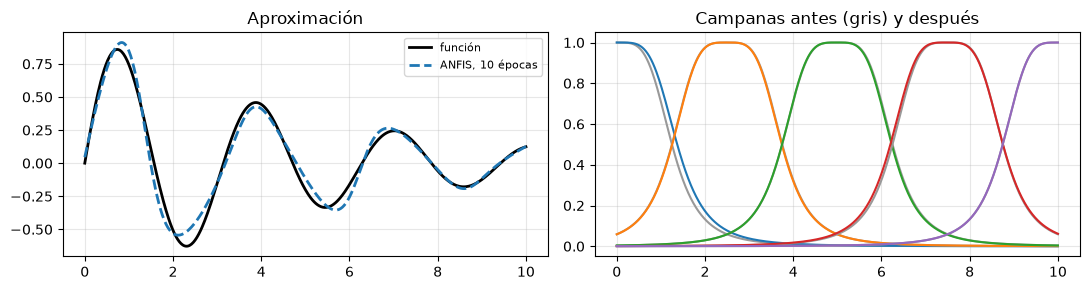

In [23]:
# PUNTO DE CONTROL 7
verificar("Las campanas iniciales coinciden con las de genfis", np.allclose(P0, P0_MATLAB), "a = rango/(2(n-1)), b = 2")
verificar("Cada época coincide con MATLAB en menos de 1e-6", np.allclose(hist_fis["rmse"], RMSE_MATLAB, atol=1e-6), "")
verificar("Las campanas finales coinciden con MATLAB en menos de 1e-5", np.allclose(P_fin, P_MATLAB, atol=1e-5), "")
xf = np.linspace(0, 10, 501)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(xf, np.sin(2 * xf) / np.exp(xf / 5), "k", lw=2, label="función")
ax[0].plot(xf, sugeno1(xf, P_fin, L_fin)[0], "--", lw=2, label="ANFIS, 10 épocas")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3); ax[0].set_title("Aproximación")
for p0, p1 in zip(P0, P_fin):
    ax[1].plot(xf, gbellmf(xf, *p0), color="0.6"); ax[1].plot(xf, gbellmf(xf, *p1))
ax[1].grid(alpha=.3); ax[1].set_title("Campanas antes (gris) y después")
plt.tight_layout(); plt.show()

**Análisis adicional.** Diez épocas dejan el error lejos de su mínimo. Se entrena 300 épocas con datos de comprobación en los puntos intermedios $x = 0.05, 0.15, \dots, 9.95$, que no entran en el ajuste pero sí deciden qué época se conserva, como hace `tunefis` cuando recibe datos de validación. La segunda parte de `referencia_tunefis_matlab.m` hace lo mismo con `anfis` de MATLAB.

RMSE de entrenamiento: época 10 0.05717, época 300 0.00370 (MATLAB 0.00370)
RMSE de comprobación mínimo 0.00333 en la época 299 (MATLAB 0.00334 en la 299)
Los primeros 24 cambios del paso coinciden con MATLAB, hasta la época 101
Paso final: 0.0013 (MATLAB 0.0020) | cambios del paso: Python 69, MATLAB 61
Campanas del sistema conservado [a b c]:
 [[1.574 2.06  0.282]
 [1.586 2.131 2.615]
 [1.542 2.074 4.893]
 [1.639 2.063 7.219]
 [1.444 1.975 9.868]]


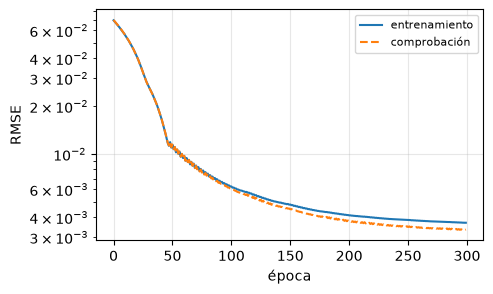

In [24]:
# ===== Análisis adicional: más épocas con datos de comprobación =====
x_val = np.round(np.arange(0.05, 10, 0.1), 10); y_val = np.sin(2 * x_val) / np.exp(x_val / 5)
hist_largo, (rmse_val_min, P_largo, L_largo, ep_largo) = anfis(x_fis, y_fis, P0, epocas=300, x_val=x_val, y_val=y_val)
cambios = [k + 1 for k in range(1, 300) if hist_largo["paso"][k] != hist_largo["paso"][k - 1]]
CAMBIOS_MATLAB = [6, 10, 14, 18, 22, 26, 30, 34, 38, 42, 46, 53, 57, 61, 65, 69, 73, 77, 81, 85, 89, 93, 97, 101, 108]
iguales = next(k for k, (a, b) in enumerate(zip(cambios, CAMBIOS_MATLAB)) if a != b)
print("RMSE de entrenamiento: época 10 %.5f, época 300 %.5f (MATLAB 0.00370)" % (hist_largo["rmse"][9], hist_largo["rmse"][-1]))
print("RMSE de comprobación mínimo %.5f en la época %d (MATLAB 0.00334 en la 299)" % (rmse_val_min, ep_largo))
print("Los primeros", iguales, "cambios del paso coinciden con MATLAB, hasta la época", cambios[iguales - 1])
print("Paso final: %.4f (MATLAB 0.0020) | cambios del paso: Python %d, MATLAB 61" % (hist_largo["paso"][-1], len(cambios)))
print("Campanas del sistema conservado [a b c]:\n", np.round(P_largo, 3))
plt.figure(figsize=(5, 3))
plt.semilogy(hist_largo["rmse"], label="entrenamiento"); plt.semilogy(hist_largo["rmse_val"], "--", label="comprobación")
plt.xlabel("época"); plt.ylabel("RMSE"); plt.grid(alpha=.3); plt.legend(fontsize=8); plt.show()